# 동적 오케스트레이터와 워커

**이 노트북에서 할 일**

1. 계획 모델에게 과제를 작업 목록으로 나누게 하고, 코드로 작업 목록을 거릅니다.
2. 거른 작업마다 작업 요청을 만들어 함께 보내고, 받은 답을 종합 요청으로 엮습니다.
3. 종합 답에 공통 사실에 없는 주소나 숫자가 있는지 정규식 규칙으로 검사합니다.
4. 과제 글만 바꿔 같은 흐름 함수를 실행하고, 작업 목록과 요청 수를 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청 수는 계획 모델이 정한 작업 수에 따라 달라집니다.
흐름 한 번은 계획 요청 1번, 작업 수만큼의 작업 요청, 종합 요청 1번입니다.
작업 수는 코드가 4개까지로 묶고, 이 노트북은 흐름을 두 번 실행해 많아야 12번 보냅니다.
교재 출력을 만든 실행에서는 11번 보냈습니다.

토큰 수를 출력하는 요청은 11번 가운데 여섯 번입니다.
10절 흐름은 노트북 밖에서 같은 과제 글로 보낸 기록의 토큰 수로 보았습니다.
그렇게 요금표를 곱해 어림한 예상 비용은 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

자료 파일을 읽거나 새 파일을 쓰지 않습니다.
01·03절에서 배운 함수 넷은 같은 폴더의 도구 파일 `workflow_tools.py`에서 가져옵니다.
걸린 시간은 재지 않습니다. 교재 출력을 만든 실행에서는 노트북 전체가 약 12초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~5절을 읽습니다.
계획 모델이 쓴 작업 목록을 코드가 거르는 자리입니다.
6~10절은 작업 요청을 함께 보내고, 종합 답을 검사하고, 흐름 함수로 묶는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 과제 글과 공통 사실에서 보라 상자 gpt-5.4-mini 계획 요청 작업 목록을 씀을 지나 파란 상자 pick_tasks 칸 둘 검사 최대 작업 수 4로 이어지고 거기서 점선 둘이 나와 작업 둘 이상이면 보라 상자 gpt-5.4-mini 작업 요청들 작업 수만큼 함께 보냄과 보라 상자 gpt-5.4-mini 종합 요청 작업 답을 한 단락으로를 지나 노란 상자 안내문과 주소 숫자 검사로 가고 둘보다 적으면 회색 상자 멈춤 작업 요청 없음 이번에 실행하지 않음으로 가는 그림](attachment:04-1-작업-나눠-맡기기의-차례.png)

위에서 아래로 읽습니다. 보라 상자 셋이 이 절에서 보내는 요청 세 가지입니다.
파란 상자에서 나온 점선은 작업 수에 따라 한쪽으로만 갑니다. 회색 멈춤 갈래는 이번에 실행하지 않았습니다.
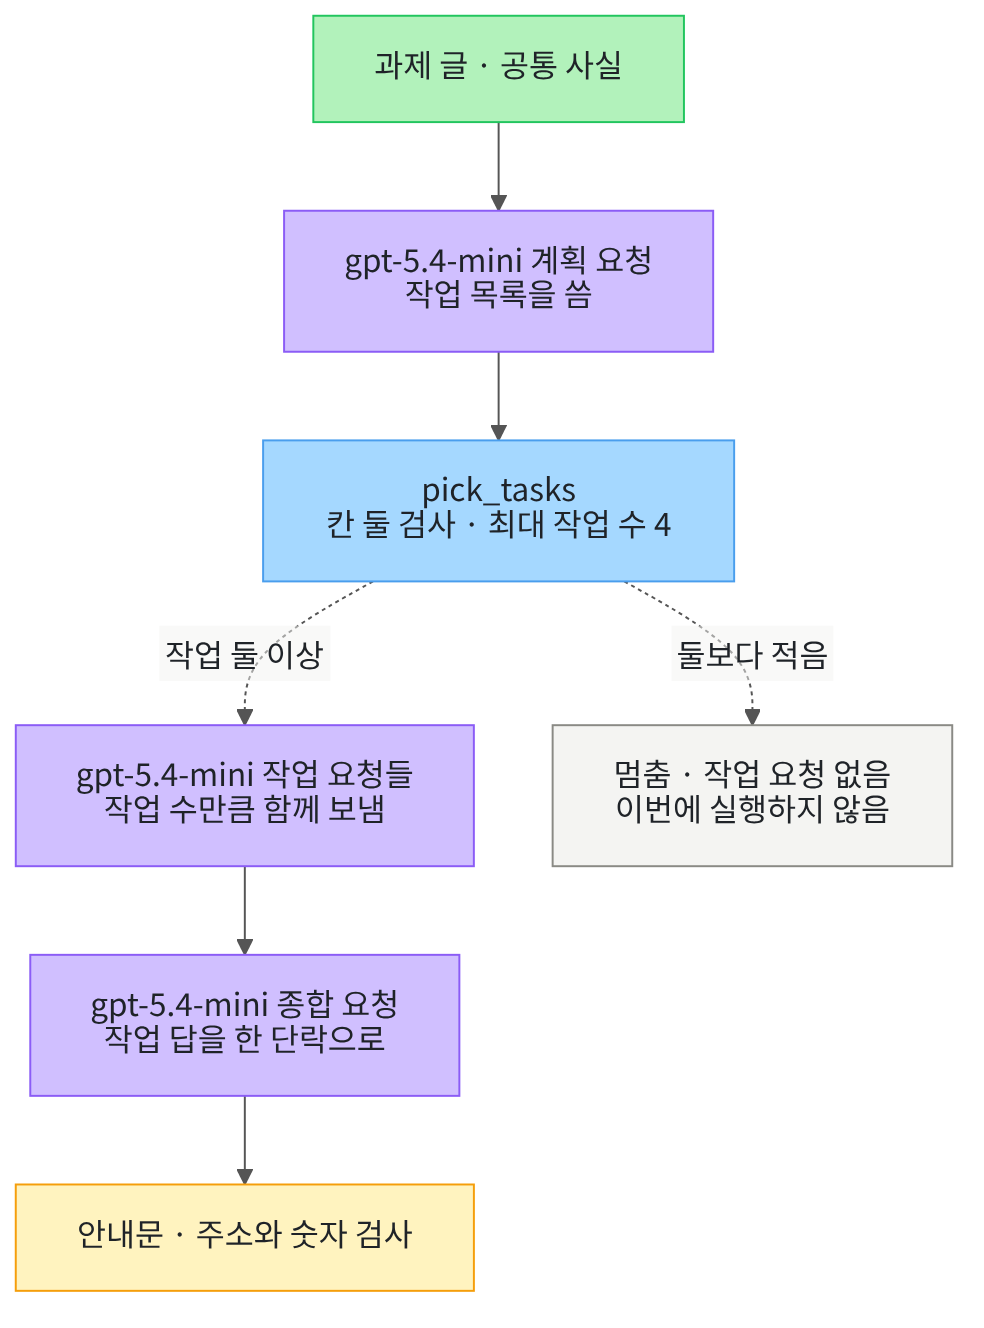

## 1. 준비

제목의 오케스트레이터(orchestrator)는 일을 나눠 맡기고 결과를 엮는 쪽입니다.
워커(worker)는 나눠 받은 일을 하는 쪽입니다.
이 절은 둘을 각각 「계획 모델」과 「작업 모델」이라고 부릅니다.
둘 다 같은 모델 `gpt-5.4-mini`이고, 지시 글만 다릅니다.

이 모양 전체는 「작업 나눠 맡기기(orchestrator-workers)」라고 부릅니다.
제목의 「동적」은 작업 목록을 코드에 미리 적지 않고, 입력을 보고 모델이 정한다는 뜻입니다.
첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `workflow_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
다음 셀은 정규식 모듈과 클라이언트 이름, 01·03절에서 배운 함수 넷을 가져옵니다.

In [2]:
# 정규식 모듈 re와 클라이언트 이름 OpenAI, 01·03절 함수 넷을 가져옵니다
import re

from openai import OpenAI

from workflow_tools import ask_all_together, ask_json, join_parts, print_records

print("불러온 이름:", "re", "OpenAI", "ask_all_together", "ask_json", "join_parts", "print_records")

불러온 이름: re OpenAI ask_all_together ask_json join_parts print_records


**결과 읽기** — 출력 줄 `불러온 이름: re OpenAI ask_all_together ask_json join_parts print_records`로 이름 여섯을 가져왔습니다.
모듈 `re`는 Ch 16 02절에서 개인정보 모양을 찾을 때 쓴 정규식 모듈입니다.
함수 `ask_json`과 `print_records`는 01절에서 배웠습니다.
함수 `ask_all_together`는 03절에서 배운 함수로, 요청 목록을 함께 보내고 받은 답을 넣은 차례로 내놓습니다.
함수 `join_parts`도 03절 함수로, 받은 답마다 칸 「글」을 꺼내 한 줄씩 잇습니다.

## 2. 키와 클라이언트 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

다음 셀은 01·03절처럼 `client = OpenAI()` 한 줄로 클라이언트를 만듭니다.
이 절도 03절처럼 이 클라이언트 하나를 여러 스레드가 함께 씁니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 하나 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)

클라이언트: OpenAI


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
클라이언트 하나를 여러 스레드가 함께 써도 되는지는 03절에서 설치한 판의 설명과 실행으로 확인했습니다.

## 3. 과제와 공통 사실 — 계획 모델에게 줄 재료

이 절도 03절처럼 2단계 인증 안내문을 씁니다.
다만 안내문을 어떤 작업으로 나눌지는 코드에 적지 않고 계획 모델에게 맡깁니다.
다음 셀은 03절과 같은 공통 사실을 적습니다. 이 절의 모든 요청이 이 공통 사실을 씁니다.

In [5]:
# 모든 요청이 함께 쓸 공통 사실을 적습니다(03절과 같은 날짜·까닭·등록 방법·문의처)
notice_fact = "2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. "
notice_fact = notice_fact + "비밀번호만으로는 계정을 지키기 어렵기 때문입니다. "
notice_fact = notice_fact + "등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. "
notice_fact = notice_fact + "문의는 help@company.test로 받습니다."
print("공통 사실:")
print(notice_fact)

공통 사실:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `공통 사실:` 아래 한 줄이 03절과 같은 공통 사실입니다.
날짜, 까닭, 등록 방법, 문의처가 한 문장씩 들어 있습니다.
문의처 `help@company.test`는 연습용 주소입니다.
8절에서는 안내문에 이 주소 말고 다른 주소가 들어갔는지 코드로 검사합니다.

다음 셀은 계획 모델의 지시 글입니다.
과제를 서로 기다리지 않는 작업으로 나누고, 작업 수는 2~4개로 정하게 합니다.

In [6]:
# 계획 모델의 지시 글을 적습니다: 과제를 서로 기다리지 않는 작업 2~4개로 나누게 합니다
plan_instructions = "사내 안내문 과제를 작업으로 나누는 계획 모델입니다. "
plan_instructions = plan_instructions + "과제와 공통 사실을 읽고, 서로의 글을 기다리지 않고 따로 쓸 수 있는 작업으로 나눕니다. "
plan_instructions = plan_instructions + "작업은 2개 이상 4개 이하로 정합니다. "
# 작업마다 칸 「이름」과 「맡을 일」을 두게 해, 코드가 두 칸으로 작업 요청을 만들 수 있게 합니다
plan_instructions = plan_instructions + '답은 JSON 객체 하나로만 출력합니다: {"작업": [{"이름": "짧은 작업 이름", "맡을 일": "한 문장"}]}'
print("계획 지시 글:")
print(plan_instructions)

계획 지시 글:
사내 안내문 과제를 작업으로 나누는 계획 모델입니다. 과제와 공통 사실을 읽고, 서로의 글을 기다리지 않고 따로 쓸 수 있는 작업으로 나눕니다. 작업은 2개 이상 4개 이하로 정합니다. 답은 JSON 객체 하나로만 출력합니다: {"작업": [{"이름": "짧은 작업 이름", "맡을 일": "한 문장"}]}


**결과 읽기** — 라벨 줄 `계획 지시 글:` 아래 한 줄이 계획 모델의 지시 글입니다.
끝에 답 모양 `{"작업": [{"이름": "짧은 작업 이름", "맡을 일": "한 문장"}]}`을 적었습니다.
칸 「작업」은 작업 딕셔너리의 목록이고, 작업마다 칸 「이름」과 「맡을 일」을 둡니다.
작업을 몇 개 쓸지는 모델이 정하고, 지시 글은 2개 이상 4개 이하라는 범위만 줍니다.

다음 셀은 과제 글을 적고 계획 요청 글을 만듭니다.
02절에서 본 것처럼 요청 머리글에 JSON이라는 말을 넣습니다.

In [7]:
# 과제 글을 적고, 요청 머리글과 공통 사실을 붙여 계획 요청 글을 만듭니다(머리글에 JSON이라는 말을 넣습니다)
task_text = "신입 직원이 처음 읽을 2단계 인증 안내문을 쓰세요. 적용 날짜, 까닭, 등록 방법, 문의처를 따로따로 담습니다."
plan_head = "아래 과제를 작업으로 나눠 JSON으로 답하세요.\n과제: "
plan_request = plan_head + task_text + "\n공통 사실: " + notice_fact
print("계획 요청 글:")
print(plan_request)

계획 요청 글:
아래 과제를 작업으로 나눠 JSON으로 답하세요.
과제: 신입 직원이 처음 읽을 2단계 인증 안내문을 쓰세요. 적용 날짜, 까닭, 등록 방법, 문의처를 따로따로 담습니다.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `계획 요청 글:` 아래 세 줄이 계획 요청 글입니다.
첫 줄은 요청 머리글이고, 둘째 줄이 과제 글, 셋째 줄이 공통 사실입니다.
과제 글은 적용 날짜, 까닭, 등록 방법, 문의처를 따로따로 담으라고 합니다.
작업을 몇 개로 나눌지와 작업 이름은 과제 글에 적지 않았습니다.

## 4. 계획 요청 — 계획 모델이 작업 목록을 씁니다

계획 모델에게 요청을 한 번 보내 작업 목록을 받습니다.
기록 목록 `records`는 이 절의 계획·작업·종합 요청이 함께 씁니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [8]:
# 계획 모델에 요청을 한 번 보내 작업 목록을 받습니다(모델 요청 1번)
records = []
plan = ask_json(client, records, "계획", plan_instructions, plan_request)
print("받은 작업 수:", len(plan["작업"]))
# 작업 딕셔너리를 한 줄씩 그대로 출력합니다(칸이 빠진 작업이 있어도 멈추지 않게)
print("작업 목록:")
for task in plan["작업"]:
    print(task)

받은 작업 수: 4
작업 목록:
{'이름': '적용 안내', '맡을 일': '2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용한다는 날짜와 적용 범위를 정리한다.'}
{'이름': '도입 이유', '맡을 일': '비밀번호만으로는 계정을 지키기 어렵다는 까닭을 짧고 분명하게 설명한다.'}
{'이름': '등록 방법', '맡을 일': '사내 포털의 보안 메뉴에서 인증 앱을 연결하는 등록 절차를 안내한다.'}
{'이름': '문의처', '맡을 일': '문의 이메일 help@company.test를 안내문에 넣어 추가 질문을 받을 수 있게 한다.'}


**결과 읽기** — 출력 줄 `받은 작업 수: 4`로 계획 모델이 작업 넷을 썼습니다.
라벨 줄 `작업 목록:` 아래 네 줄이 작업 딕셔너리이고, 작업마다 칸 「이름」과 「맡을 일」이 있습니다.
작업 이름은 적용 안내, 도입 이유, 등록 방법, 문의처입니다.
이 목록은 코드가 아니라 모델의 답에서 왔습니다.

칸 「맡을 일」의 문장은 실행마다 달라질 수 있습니다.
작업 수와 작업 이름도 실행한 때에 따라 달라질 수 있습니다.
노트북 밖에서 같은 요청을 다섯 번 보냈을 때는 다섯 번 모두 이 네 이름이었습니다.

작업 넷은 과제 글이 따로따로 담으라고 한 네 항목과 하나씩 짝이 맞습니다.
과제 글이 담을 것을 나눠 적어, 작업 수를 사실상 정해 준 셈입니다.
과제 글에 없는 작업을 모델이 더하는 모습은 10절에서 봅니다.

## 5. 작업 목록 거르기 — 코드가 검사합니다

계획 모델의 답은 약속한 모양이 아닐 수 있습니다.
칸이 빠진 작업이 있거나, 작업이 너무 많거나 적을 수 있습니다.
01절 게이트처럼, 다음 단계로 넘기기 전에 코드로 거릅니다.
다음 셀은 두 칸이 모두 있는 작업만, 정한 수까지 골라 내놓는 함수입니다.

In [9]:
# 계획의 작업 가운데 칸 「이름」과 「맡을 일」이 모두 있는 것만, 정한 수까지 골라 내놓습니다
def pick_tasks(plan, max_tasks):
    tasks = []
    for task in plan["작업"]:
        # 작업 요청을 만들 때 두 칸을 모두 쓰므로, 하나라도 없으면 뺍니다
        if "이름" in task and "맡을 일" in task:
            tasks.append(task)
    # 정한 수보다 많으면 앞에서부터 그 수만큼만 씁니다
    return tasks[:max_tasks]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `pick_tasks`는 계획 딕셔너리와 최대 작업 수를 받습니다.
칸 「이름」과 「맡을 일」이 모두 있는 작업만 새 목록에 담습니다.
마지막 줄의 `[:max_tasks]`는 Ch 2에서 배운 목록 자르기로, 앞에서부터 그 수만큼만 남깁니다.

다음 셀은 손으로 적은 계획 둘로 이 함수를 확인합니다.
모델 글이 아니라 미리 정한 값이라 `assert`로 확인할 수 있습니다.

In [10]:
# 손으로 적은 계획 둘로 작업 거르기를 확인합니다(정해 둔 값이라 assert로 봅니다)
full_task = {"이름": "날짜 알림", "맡을 일": "적용 날짜를 알립니다"}
long_plan = {"작업": [full_task, {"이름": "빈 작업"}, full_task, full_task, full_task, full_task]}
thin_plan = {"작업": [full_task, {"이름": "빈 작업"}]}
long_tasks = pick_tasks(long_plan, 4)
thin_tasks = pick_tasks(thin_plan, 4)
print("작업 여섯(칸 빠진 작업 하나) → 남은 작업 수:", len(long_tasks))
print("작업 둘(칸 빠진 작업 하나) → 남은 작업 수:", len(thin_tasks))
assert len(long_tasks) == 4
assert len(thin_tasks) == 1

작업 여섯(칸 빠진 작업 하나) → 남은 작업 수: 4
작업 둘(칸 빠진 작업 하나) → 남은 작업 수: 1


**결과 읽기** — 출력 줄 `작업 여섯(칸 빠진 작업 하나) → 남은 작업 수: 4`는 칸 빠진 작업을 뺀 다섯 가운데 앞 넷입니다.
출력 줄 `작업 둘(칸 빠진 작업 하나) → 남은 작업 수: 1`은 쓸 수 있는 작업이 하나뿐인 경우입니다.
두 `assert` 줄도 통과했습니다.

작업이 하나뿐이면 나눠 맡길 까닭이 없습니다.
그래서 이 절은 최소 작업 수를 2로 두고, 그보다 적으면 작업 요청을 보내지 않고 멈춥니다.
다음 셀은 두 한도를 정하고, 4절에서 받은 계획을 거릅니다.

In [11]:
# 작업 수의 위아래 한도를 정하고, 4절에서 받은 계획을 거릅니다(모델 요청 없음)
max_tasks = 4
min_tasks = 2
tasks = pick_tasks(plan, max_tasks)
task_names = []
for task in tasks:
    task_names.append(task["이름"])
print("거른 뒤 작업 수:", len(tasks))
print("최소 작업 수 이상인가:", len(tasks) >= min_tasks)
print("작업 이름:", task_names)

거른 뒤 작업 수: 4
최소 작업 수 이상인가: True
작업 이름: ['적용 안내', '도입 이유', '등록 방법', '문의처']


**결과 읽기** — 출력 줄 `거른 뒤 작업 수: 4`로 작업 넷이 모두 남았습니다.
네 작업 모두 두 칸이 있었고, 최대 작업 수 4를 넘지 않았기 때문입니다.
출력 줄 `최소 작업 수 이상인가: True`로 작업 요청을 보낼 수 있습니다.
라벨 `작업 이름:` 뒤 목록이 6절에서 작업 요청의 단계 이름이 됩니다.

다음 셀은 03절에서 코드에 적은 부분 목록과 이 작업 목록을 나란히 봅니다.
이 셀은 모델을 부르지 않습니다.

In [12]:
# 03절에서 코드에 적은 부분 목록과, 이번에 계획 모델이 쓴 작업 목록을 나란히 봅니다(모델 요청 없음)
fixed_parts = ["목적", "절차", "문의"]
print("03절 부분 목록:", fixed_parts)
print("이번 작업 목록:", task_names)
print("두 목록이 같은가:", task_names == fixed_parts)

03절 부분 목록: ['목적', '절차', '문의']
이번 작업 목록: ['적용 안내', '도입 이유', '등록 방법', '문의처']
두 목록이 같은가: False


**결과 읽기** — 출력 줄 `03절 부분 목록: ['목적', '절차', '문의']`는 03절에서 코드에 손으로 적은 부분 이름입니다.
출력 줄 `이번 작업 목록: ['적용 안내', '도입 이유', '등록 방법', '문의처']`는 계획 모델의 답에서 온 이름입니다.
출력 줄 `두 목록이 같은가: False`로 두 목록은 다릅니다.
03절은 과제와 상관없이 부분 셋을 썼고, 이 절의 목록은 과제 글을 읽은 모델이 썼습니다.

다만 두 목록은 이름부터 달라 `False`가 나온 것입니다.
목록이 모델의 답에서 왔다는 것은 4절 셀이 `plan["작업"]`을 읽는 코드와 10절 결과로 봅니다.

## 6. 작업 요청 함께 보내기 — 작업 모델이 나눠 씁니다

거른 작업마다 작업 모델에게 보낼 요청을 만듭니다.
모든 작업 요청은 지시 글 하나를 함께 쓰고, 요청 글만 작업마다 다릅니다.
03절 나눠 쓰기와 같은 모양입니다.
다음 셀은 작업 모델의 지시 글입니다.

In [13]:
# 작업 모델의 지시 글을 적습니다: 모든 작업 요청이 이 지시 글 하나를 함께 씁니다
task_instructions = "사내 안내문의 작업 하나를 맡아 쓰는 작성자입니다. "
task_instructions = task_instructions + "공통 사실 가운데 맡은 일에 맞는 것만 골라 한국어 두 문장으로 씁니다. "
task_instructions = task_instructions + "공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. "
# 칸 「작업」에 작업 이름을 그대로 적게 해, 받은 답이 어느 작업의 답인지 알아볼 수 있게 합니다
task_instructions = task_instructions + '답은 JSON 객체 하나로만 출력합니다: {"작업": "맡을 작업 이름 그대로", "글": "글"}'
print("작업 지시 글:")
print(task_instructions)

작업 지시 글:
사내 안내문의 작업 하나를 맡아 쓰는 작성자입니다. 공통 사실 가운데 맡은 일에 맞는 것만 골라 한국어 두 문장으로 씁니다. 공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. 답은 JSON 객체 하나로만 출력합니다: {"작업": "맡을 작업 이름 그대로", "글": "글"}


**결과 읽기** — 라벨 줄 `작업 지시 글:` 아래 한 줄이 작업 모델의 지시 글입니다.
03절 작성자의 지시 글처럼 공통 사실에 없는 날짜·연락처·절차는 지어내지 않게 했습니다.
답 모양의 칸 「작업」은 받은 답이 어느 작업의 답인지 알아보려고 둔 칸입니다.

다음 셀은 작업마다 요청 딕셔너리를 만드는 함수입니다.
03절 함수 `ask_all_together`가 받는 모양대로 칸 「단계」·「지시 글」·「요청 글」을 둡니다.

In [14]:
# 작업마다 요청 딕셔너리(단계·지시 글·요청 글)를 만들어 요청 목록 하나로 내놓습니다
def build_task_requests(instructions_text, task_head, fact, tasks):
    requests = []
    for task in tasks:
        # 요청 글 = 요청 머리글 + 공통 사실 + 맡을 작업의 이름과 맡을 일
        task_lines = "\n맡을 작업: " + task["이름"] + "\n맡을 일: " + task["맡을 일"]
        request_text = task_head + fact + task_lines
        requests.append({"단계": task["이름"], "지시 글": instructions_text, "요청 글": request_text})
    return requests

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_task_requests`는 지시 글, 요청 머리글, 공통 사실, 작업 목록을 받습니다.
작업마다 요청 글을 만들고, 칸 「단계」에는 작업 이름을 넣습니다.
작업이 몇 개든 같은 코드로 요청 목록을 만듭니다.

다음 셀은 5절에서 거른 작업으로 요청 목록을 만들고, 첫 요청을 출력합니다.

In [15]:
# 5절에서 거른 작업으로 작업 요청 목록을 만듭니다(머리글에 JSON이라는 말을 넣습니다)
task_head = "아래 공통 사실로 맡은 작업의 글을 JSON으로 쓰세요.\n공통 사실: "
task_requests = build_task_requests(task_instructions, task_head, notice_fact, tasks)
first_request = task_requests[0]
print("요청 수:", len(task_requests))
print("첫 요청의 단계:", first_request["단계"])
print("첫 요청의 요청 글:")
print(first_request["요청 글"])

요청 수: 4
첫 요청의 단계: 적용 안내
첫 요청의 요청 글:
아래 공통 사실로 맡은 작업의 글을 JSON으로 쓰세요.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.
맡을 작업: 적용 안내
맡을 일: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용한다는 날짜와 적용 범위를 정리한다.


**결과 읽기** — 출력 줄 `요청 수: 4`로 작업마다 요청 딕셔너리를 하나씩 만들었습니다.
출력 줄 `첫 요청의 단계: 적용 안내`는 첫 작업의 이름입니다.
라벨 줄 `첫 요청의 요청 글:` 아래 네 줄이 첫 요청 글입니다.
요청 머리글과 공통 사실 뒤에 맡을 작업과 맡을 일이 한 줄씩 붙었습니다.

맡을 일 줄은 4절 계획 답의 문장이라 실행마다 달라질 수 있습니다.

다음 셀은 요청 목록을 03절 함수 `ask_all_together`로 함께 보냅니다.
셀 맨 위의 await 줄은 03절처럼 노트북 도구(IPython)의 기능입니다.
이 셀에서 모델 요청이 작업 수만큼 나갑니다.

In [16]:
# 작업 요청 목록을 03절 함수 ask_all_together로 함께 보냅니다(모델 요청 = 작업 수)
task_answers = await ask_all_together(client, records, task_requests)
answer_names = []
for answer in task_answers:
    answer_names.append(answer["작업"])
print("받은 답 수:", len(task_answers))
print("받은 답의 칸 「작업」 차례:", answer_names)
print("작업 이름 차례와 같은가:", answer_names == task_names)

받은 답 수: 4
받은 답의 칸 「작업」 차례: ['적용 안내', '도입 이유', '등록 방법', '문의처']
작업 이름 차례와 같은가: True


**결과 읽기** — 출력 줄 `받은 답 수: 4`로 작업 요청 넷의 답을 받았습니다.
출력 줄 `받은 답의 칸 「작업」 차례: ['적용 안내', '도입 이유', '등록 방법', '문의처']`는 작업 목록의 차례와 같습니다.
출력 줄 `작업 이름 차례와 같은가: True`로 모델은 칸 「작업」에 작업 이름을 그대로 적었습니다.
03절처럼 함수 `ask_all_together`가 내놓은 답 목록은 넣은 차례입니다.

## 7. 종합 요청 — 작업 답을 안내문 하나로 엮습니다

종합(synthesis)은 나눠 받은 답을 모아 결과 하나로 엮는 일입니다.
03절 나눠 쓰기에서는 받은 글을 코드가 줄만 바꿔 이었습니다.
이 절은 작업 답을 모델에게 한 번 더 보내 한 단락으로 엮게 합니다.
이 종합 요청도 계획 모델이 맡는 일로 봅니다.
다음 셀은 종합 요청의 지시 글입니다.

In [17]:
# 종합 요청의 지시 글을 적습니다: 작업 답을 한 단락으로 엮고, 공통 사실에 없는 연락처·번호는 쓰지 않게 합니다
summary_instructions = "작업 답들을 엮어 사내 안내문 하나로 만드는 편집자입니다. "
summary_instructions = summary_instructions + "겹치는 내용은 한 번만 남기고, 한국어 한 단락으로 씁니다. "
summary_instructions = summary_instructions + "공통 사실에 없는 날짜·연락처·번호는 쓰지 않습니다. "
summary_instructions = summary_instructions + '답은 JSON 객체 하나로만 출력합니다: {"안내문": "글"}'
print("종합 지시 글:")
print(summary_instructions)

종합 지시 글:
작업 답들을 엮어 사내 안내문 하나로 만드는 편집자입니다. 겹치는 내용은 한 번만 남기고, 한국어 한 단락으로 씁니다. 공통 사실에 없는 날짜·연락처·번호는 쓰지 않습니다. 답은 JSON 객체 하나로만 출력합니다: {"안내문": "글"}


**결과 읽기** — 라벨 줄 `종합 지시 글:` 아래 한 줄이 종합 요청의 지시 글입니다.
겹치는 내용은 한 번만 남기고 한 단락으로 쓰게 했습니다.
공통 사실에 없는 날짜·연락처·번호도 쓰지 않게 했습니다.
모델이 이 지시를 따랐는지는 8절에서 코드로 검사합니다.

다음 셀은 종합 요청 글을 만드는 함수입니다.

In [18]:
# 종합 요청 글을 만듭니다: 머리글과 공통 사실 뒤에, 받은 작업 답의 글을 차례로 이어 붙입니다
def build_summary_request(summary_head, fact, answers):
    # 03절 함수 join_parts는 답마다 칸 「글」을 꺼내 넣은 차례로 한 줄씩 잇습니다
    answers_text = join_parts(answers)
    return summary_head + fact + "\n작업 답:\n" + answers_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_summary_request`는 요청 머리글과 공통 사실 뒤에 작업 답의 글을 붙입니다.
작업 답의 글은 함수 `join_parts`가 넣은 차례대로 한 줄씩 잇습니다.

다음 셀은 종합 요청을 보내 안내문 하나를 받습니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [19]:
# 계획 모델에 종합 요청을 한 번 보내 안내문 하나를 받습니다(모델 요청 1번)
summary_head = "아래 공통 사실과 작업 답을 엮어 안내문 하나를 JSON으로 쓰세요.\n공통 사실: "
summary_request = build_summary_request(summary_head, notice_fact, task_answers)
summary = ask_json(client, records, "종합", summary_instructions, summary_request)
notice = summary["안내문"]
print("안내문:")
print(notice)

안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증이 적용됩니다. 비밀번호만으로는 계정을 지키기 어렵기 때문에 보안을 강화하기 위한 조치이며, 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 완료됩니다. 문의는 help@company.test로 보내 주시기 바랍니다.


**결과 읽기** — 라벨 줄 `안내문:` 아래 한 줄이 종합 요청으로 받은 안내문입니다.
작업 넷의 답을 한 단락으로 엮었고, 공통 사실의 주소 `help@company.test`가 들어 있습니다.

안내문 글은 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
교재 출력에서는 날짜, 까닭, 등록 방법, 문의처를 세 문장에 담았습니다.

다음 셀은 이 절에서 보낸 요청의 기록 줄을 출력합니다.
요청 수를 작업 수로 셈한 값도 함께 봅니다.

In [20]:
# 계획·작업·종합 요청의 기록 줄을 출력하고, 요청 수를 작업 수로 셈한 값과 견줍니다(모델 요청 없음)
expected_count = 1 + len(tasks) + 1
print("요청 수(기록 줄 수):", len(records))
print("1 + 작업 수 + 1:", expected_count)
print_records(records)

요청 수(기록 줄 수): 6
1 + 작업 수 + 1: 6
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 계획 | 232 | 161
2 | 등록 방법 | 219 | 54
3 | 문의처 | 218 | 54
4 | 도입 이유 | 224 | 57
5 | 적용 안내 | 231 | 72
6 | 종합 | 349 | 90


**결과 읽기** — 출력 줄 `요청 수(기록 줄 수): 6`과 `1 + 작업 수 + 1: 6`이 같습니다.
계획 요청 한 번, 작업 요청 네 번, 종합 요청 한 번입니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 첫 줄 `1 | 계획 | 232`가 계획 요청입니다.
마지막 줄은 종합 요청이고, 가운데 네 줄은 03절처럼 응답이 도착한 차례로 쌓인 작업 요청입니다.

작업 요청 줄의 차례와 토큰 수는 실행마다 달라질 수 있습니다.
교재 출력에서는 등록 방법, 문의처, 도입 이유, 적용 안내 차례로 쌓였습니다.
어느 줄이 어느 작업인지는 칸 「단계」로 찾습니다.

## 8. 종합 답 검사 — 공통 사실에 없는 주소와 숫자

지시 글에 쓰지 말라고 적어도, 모델이 공통 사실에 없는 연락처를 쓸 수 있습니다.
그래서 종합 답을 코드 규칙으로 한 번 더 검사합니다.
규칙은 Ch 16 02절에서 배운 정규식과 함수 `re.findall`로 적습니다.
종합 답에서 주소 모양과 숫자 모양을 찾고, 공통 사실에 없는 것을 골라냅니다.

- 주소 모양 정규식의 대괄호 `[a-z]`는 영문 소문자 한 글자입니다. Ch 16 02절 `[1-4]`와 같은 범위 표기입니다.
- 역슬래시를 붙인 `\.`는 점 글자 그대로입니다. 대괄호 밖의 점은 아무 글자 하나라는 뜻이라 역슬래시를 붙였습니다.
- 숫자 모양 정규식 `\d+`는 숫자 한 글자 이상이 이어진 덩어리입니다.
- Ch 16 02절 이메일 정규식의 `\w`는 한글도 받아, 주소 뒤 조사까지 묶었습니다. 그래서 영문 소문자만 받게 했습니다.

In [21]:
# 주소 모양과 숫자 모양의 정규식을 적고, 공통 사실에서 먼저 찾아 봅니다
address_pattern = r"[a-z]+@[a-z]+\.[a-z]+"
number_pattern = r"\d+"
contact_patterns = [address_pattern, number_pattern]
print("공통 사실의 주소:", re.findall(address_pattern, notice_fact))
print("공통 사실의 숫자:", re.findall(number_pattern, notice_fact))

공통 사실의 주소: ['help@company.test']
공통 사실의 숫자: ['2026', '10', '15', '2']


**결과 읽기** — 출력 줄 `공통 사실의 주소: ['help@company.test']`로 주소 하나를 찾았습니다.
주소 뒤 조사 「로」는 `[a-z]`에 맞지 않아 빠졌습니다.
출력 줄 `공통 사실의 숫자: ['2026', '10', '15', '2']`는 날짜와 「2단계」의 숫자입니다.
이 두 목록에 없는 주소나 숫자가 종합 답에 있으면 공통 사실 밖의 값으로 봅니다.

다음 셀은 그 규칙을 함수로 적습니다.

In [22]:
# 검사할 글에서 정규식에 맞는 값 가운데, 공통 사실에서는 찾을 수 없는 것만 목록으로 내놓습니다
def find_new_contacts(text, fact, patterns):
    new_items = []
    for pattern in patterns:
        # 같은 정규식으로 공통 사실에서 찾은 목록에 없으면 공통 사실 밖의 값입니다
        fact_items = re.findall(pattern, fact)
        for item in re.findall(pattern, text):
            if item not in fact_items:
                new_items.append(item)
    return new_items

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `find_new_contacts`는 검사할 글, 공통 사실, 정규식 목록을 받습니다.
정규식마다 공통 사실에서 먼저 찾고, 검사할 글에서 찾은 값 가운데 거기 없는 것만 모읍니다.
모델을 부르지 않으므로 같은 글에는 늘 같은 목록을 내놓습니다.

다음 셀은 손으로 적은 글 둘로 규칙을 확인합니다.
하나는 공통 사실에 없는 내선 번호와 주소를 지어 넣은 글이고, 하나는 공통 사실만 쓴 글입니다.

In [23]:
# 손으로 적은 글 둘로 검사 규칙을 확인합니다(정해 둔 값이라 assert로 봅니다)
made_up = "등록이 어려우면 내선 1234나 helpdesk@company.com으로 문의해 주세요."
kept = "10월 15일 전에 등록하고, 문의는 help@company.test로 보내 주세요."
made_up_items = find_new_contacts(made_up, notice_fact, contact_patterns)
kept_items = find_new_contacts(kept, notice_fact, contact_patterns)
print("지어낸 연락처가 든 글:", made_up_items)
print("공통 사실만 쓴 글:", kept_items)
assert made_up_items == ["helpdesk@company.com", "1234"]
assert kept_items == []

지어낸 연락처가 든 글: ['helpdesk@company.com', '1234']
공통 사실만 쓴 글: []


**결과 읽기** — 출력 줄 `지어낸 연락처가 든 글: ['helpdesk@company.com', '1234']`로 지어낸 주소와 내선 번호를 모두 찾았습니다.
출력 줄 `공통 사실만 쓴 글: []`은 날짜 숫자와 주소가 모두 공통 사실에 있어 빈 목록입니다.
두 `assert` 줄도 통과했습니다.

다음 셀은 7절에서 받은 종합 답을 같은 규칙으로 검사합니다.
이 셀은 모델을 부르지 않습니다.

In [24]:
# 7절에서 받은 종합 답을 같은 규칙으로 검사합니다(모델 요청 없음)
new_items = find_new_contacts(notice, notice_fact, contact_patterns)
print("공통 사실에 없는 주소·숫자:", new_items)
print("공통 사실의 주소가 들어 있는가:", "help@company.test" in notice)

공통 사실에 없는 주소·숫자: []
공통 사실의 주소가 들어 있는가: True


**결과 읽기** — 출력 줄 `공통 사실에 없는 주소·숫자: []`로 종합 답에서 공통 사실 밖의 주소나 숫자를 찾지 못했습니다.
출력 줄 `공통 사실의 주소가 들어 있는가: True`로 문의처 주소는 들어 있습니다.
이 결과는 이번에 받은 종합 답 하나를 검사한 것입니다.

모델이 쓴 글이라 다른 실행에서는 다른 결과가 나올 수 있습니다.
노트북 밖에서 과제 글 셋으로 흐름을 다섯 번씩 보내 보았습니다.
그때 받은 종합 답 열다섯 개도 모두 빈 목록이었습니다.
빈 목록이 나와도, 이 규칙이 보는 것은 주소와 숫자 모양뿐입니다.

## 9. 흐름 함수로 묶기

4~7절에서 한 차례를 함수로 묶어, 과제 글만 바꿔 다시 쓸 수 있게 합니다.
먼저 계획 요청을 보내고 작업 목록을 거르는 함수를 만듭니다.
계획 요청 글은 3절과 같은 식으로 만듭니다.

In [25]:
# 계획 요청을 한 번 보내고, 받은 계획을 거른 작업 목록을 내놓습니다(모델 요청 1번)
def plan_tasks(client, records, setup, task_text, fact):
    plan_request = setup["계획 머리글"] + task_text + "\n공통 사실: " + fact
    plan = ask_json(client, records, "계획", setup["계획 지시 글"], plan_request)
    return pick_tasks(plan, setup["최대 작업 수"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `plan_tasks`는 계획 요청을 한 번 보내고, 받은 계획을 함수 `pick_tasks`로 거른 작업 목록을 내놓습니다.
요청 머리글과 지시 글, 최대 작업 수는 설정 딕셔너리 `setup`에서 꺼냅니다.

다음 셀은 작업 나눠 맡기기 흐름 함수입니다.
작업이 최소 작업 수보다 적으면 01절 게이트처럼 작업 요청을 보내기 전에 멈춥니다.
함수 안에서 await를 쓰므로 03절처럼 정의 줄을 `async def`로 씁니다.

In [26]:
# 작업 나눠 맡기기 흐름: 계획 → 작업 요청들을 함께 → 종합의 차례를 코드가 정합니다(모델 요청 = 1 + 작업 수 + 1)
async def run_orchestrator(client, records, setup, task_text, fact):
    tasks = plan_tasks(client, records, setup, task_text, fact)
    # 작업이 최소 작업 수보다 적으면 작업 요청을 보내기 전에 멈춥니다
    if len(tasks) < setup["최소 작업 수"]:
        return {"상태": "멈춤", "작업": tasks, "답": [], "안내문": ""}
    requests = build_task_requests(setup["작업 지시 글"], setup["작업 머리글"], fact, tasks)
    answers = await ask_all_together(client, records, requests)
    summary_request = build_summary_request(setup["종합 머리글"], fact, answers)
    summary = ask_json(client, records, "종합", setup["종합 지시 글"], summary_request)
    return {"상태": "완료", "작업": tasks, "답": answers, "안내문": summary["안내문"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_orchestrator`는 계획, 작업 목록 거르기, 작업 요청 함께 보내기, 종합 요청을 차례로 합니다.
이 차례는 함수 코드에 적혀 있어 실행마다 같습니다.
달라지는 것은 계획 모델이 쓴 작업 목록, 곧 작업 요청의 수와 맡을 일입니다.
흐름 결과에는 01~03절처럼 칸 「상태」를 둡니다.

Ch 17 01절 규칙으로 이 흐름을 가르면 워크플로우입니다.
이 챕터의 기록 줄에는 다음 단계를 고른 쪽을 적는 칸이 없습니다.
계획 다음에 작업 요청을, 그다음에 종합 요청을 보내라고 고르는 쪽이 모두 코드이기 때문입니다.
모델이 쓴 작업 목록은 02절에서 모델이 쓴 종류처럼, 코드가 받아 쓰는 값입니다.
다음 셀은 이 흐름에 쓸 설정 한 벌을 모읍니다.

In [27]:
# 나눠 맡기기 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다(3~7절에서 적은 값 그대로)
orchestrator_setup = {
    "계획 지시 글": plan_instructions, "계획 머리글": plan_head,
    "최대 작업 수": max_tasks, "최소 작업 수": min_tasks,
    "작업 지시 글": task_instructions, "작업 머리글": task_head,
    "종합 지시 글": summary_instructions, "종합 머리글": summary_head,
}
setup_keys = list(orchestrator_setup.keys())
print("설정 칸 수:", len(setup_keys))
print("설정 칸:", setup_keys)

설정 칸 수: 8
설정 칸: ['계획 지시 글', '계획 머리글', '최대 작업 수', '최소 작업 수', '작업 지시 글', '작업 머리글', '종합 지시 글', '종합 머리글']


**결과 읽기** — 출력 줄 `설정 칸 수: 8`로 여덟 칸을 모았습니다.
라벨 `설정 칸:` 뒤 목록은 계획·작업·종합 요청의 지시 글과 머리글, 작업 수의 두 한도입니다.
값은 3~7절에서 적은 것을 그대로 넣었습니다.

## 10. 값 바꿔 보기 · 과제 글 바꾸기

바꿀 값은 과제 글 하나입니다.
등록 방법만 짧게 알리는 안내문을 쓰라고 바꿉니다.
공통 사실과 설정은 그대로 두고, 9절 흐름 함수를 실행합니다.

실행 전에 예상해 봅니다.
담을 것이 줄었으니 계획 모델이 작업을 더 적게 나눌 것입니다.
작업이 줄면 작업 요청도 줄고, 요청 수는 여전히 1 + 작업 수 + 1일 것입니다.
이 셀에서 모델 요청이 1 + 작업 수 + 1번 나갑니다.

In [28]:
# 과제 글 하나만 바꿔 흐름 함수를 실행합니다(모델 요청 = 1 + 작업 수 + 1)
short_task_text = "2단계 인증 등록 방법만 짧게 알리는 안내문을 쓰세요."
short_records = []
short_result = await run_orchestrator(client, short_records, orchestrator_setup, short_task_text, notice_fact)
short_names = []
for task in short_result["작업"]:
    short_names.append(task["이름"])
print("상태:", short_result["상태"])
print("작업 이름:", short_names)
print("작업 수(4~7절 → 10절):", len(tasks), len(short_names))
print("요청 수(4~7절 → 10절):", len(records), len(short_records))

상태: 완료
작업 이름: ['핵심 메시지 정리', '등록 방법 작성', '문의처 표기']
작업 수(4~7절 → 10절): 4 3
요청 수(4~7절 → 10절): 6 5


**결과 읽기** — 출력 줄 `상태: 완료`로 흐름 함수가 계획부터 종합까지 마쳤습니다.
출력 줄 `작업 수(4~7절 → 10절): 4 3`으로 과제 글을 바꾸자 작업이 넷에서 셋으로 줄었습니다.
출력 줄 `요청 수(4~7절 → 10절): 6 5`는 두 흐름 모두 1 + 작업 수 + 1입니다.
예상대로 같은 차례와 설정이 과제 글에 따라 다른 작업 목록을 실행했습니다.

라벨 `작업 이름:` 뒤 목록은 실행마다 달라질 수 있습니다.
교재 출력에서는 핵심 메시지 정리, 등록 방법 작성, 문의처 표기였습니다.
과제 글은 등록 방법만 담으라고 했지만, 계획 모델은 공지 요지와 문의처 작업도 두었습니다.

다음 셀은 바꾼 과제의 안내문을 출력하고, 8절 규칙으로 검사합니다.
이 셀은 모델을 부르지 않습니다.

In [29]:
# 바꾼 과제의 안내문을 출력하고, 8절 규칙으로 검사합니다(모델 요청 없음)
short_notice = short_result["안내문"]
short_items = find_new_contacts(short_notice, notice_fact, contact_patterns)
print("안내문:")
print(short_notice)
print("공통 사실에 없는 주소·숫자:", short_items)

안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증이 적용됩니다. 비밀번호만으로는 계정을 지키기 어렵기 때문에 보안을 강화하기 위한 조치이며, 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 완료됩니다. 문의는 help@company.test로 보내주시기 바랍니다.
공통 사실에 없는 주소·숫자: []


**결과 읽기** — 라벨 줄 `안내문:` 아래 한 줄이 바꾼 과제로 받은 안내문입니다.
출력 줄 `공통 사실에 없는 주소·숫자: []`로 이 안내문에서도 공통 사실 밖의 주소나 숫자를 찾지 못했습니다.

안내문 글은 실행마다 달라질 수 있습니다.
교재 출력의 안내문은 등록 방법만이 아니라 날짜와 까닭, 문의처도 담았습니다.

이 절의 종합 요청 글에는 과제 글이 들어가지 않고, 공통 사실 전체와 작업 답이 들어갑니다.
그래서 종합 요청은 「등록 방법만 짧게」라는 과제 글을 받지 않았습니다.
06절에서는 종합 머리글에 과제 글을 넣습니다.

## 정리

1. 계획 모델이 과제를 읽고 작업 목록을 썼고, 코드는 두 칸이 있는 작업만 최대 작업 수까지 걸렀습니다.
2. 차례는 코드가 정했고, 작업 수와 맡을 일은 모델이 정해 요청 수가 1 + 작업 수 + 1이 되었습니다.
3. 종합 답은 정규식 규칙으로 검사했고, 과제 글을 바꾸자 같은 흐름이 다른 작업 목록을 실행했습니다.

05절에서는 글을 쓰는 요청과 평가하는 요청을 번갈아 보내고, 코드가 정한 조건으로 멈춥니다.